In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:

import pandas as pd

url = "https://raw.githubusercontent.com/tejatanush/House-Price-Prediction/main/Housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,4410000,4900,2,1,2,yes,no,yes,no,no,0,no,semi-furnished
1,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished
2,5110000,6100,3,1,1,yes,no,yes,no,yes,0,yes,semi-furnished
3,3780000,2856,3,1,3,yes,no,no,no,no,0,yes,furnished
4,5810000,5828,4,1,4,yes,yes,no,no,no,0,no,semi-furnished


In [4]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (545, 13)
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


In [5]:

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,4410000,4900,2,1,2,yes,no,yes,no,no,0,no,semi-furnished
1,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished
2,5110000,6100,3,1,1,yes,no,yes,no,yes,0,yes,semi-furnished
3,3780000,2856,3,1,3,yes,no,no,no,no,0,yes,furnished
4,5810000,5828,4,1,4,yes,yes,no,no,no,0,no,semi-furnished


In [6]:

print("Number of rows and columns:", df.shape)

Number of rows and columns: (545, 13)


In [7]:

print(df.columns)

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')


In [8]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [9]:

df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [10]:

print(df.isnull().sum())

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [11]:

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [12]:

df = df.drop_duplicates()

print("Duplicate records removed!")

Duplicate records removed!


In [13]:

df = pd.get_dummies(df, drop_first=True, dtype=int)

print("Text values converted into numbers!")

df.head()


Text values converted into numbers!


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,4410000,4900,2,1,2,0,1,0,1,0,0,0,1,0
1,1750000,3850,3,1,2,0,1,0,0,0,0,0,0,1
2,5110000,6100,3,1,1,0,1,0,1,0,1,1,1,0
3,3780000,2856,3,1,3,0,1,0,0,0,0,1,0,0
4,5810000,5828,4,1,4,0,1,1,0,0,0,0,1,0


In [14]:

X = df.drop("price", axis=1)

y = df["price"]

print("Input features:")
print(X.columns)

print("\nTarget variable: price")

Input features:
Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes',
       'guestroom_yes', 'basement_yes', 'hotwaterheating_yes',
       'airconditioning_yes', 'prefarea_yes',
       'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished'],
      dtype='object')

Target variable: price


In [15]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (436, 13)
Testing data: (109, 13)


In [16]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [17]:

predictions = model.predict(X_test)

print("First 10 Predicted House Prices:")

print(predictions[:10])

First 10 Predicted House Prices:
[5077528.86605601 2798234.42980105 3768307.76677463 3123380.41465366
 3173815.71941685 3128338.0950796  4451745.92358187 5031189.70119303
 2696766.78555689 6614098.48043086]


In [18]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, predictions)

r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)

print("R2 Score:", r2)

Mean Absolute Error: 703628.3789428121
R2 Score: 0.6953051655829486


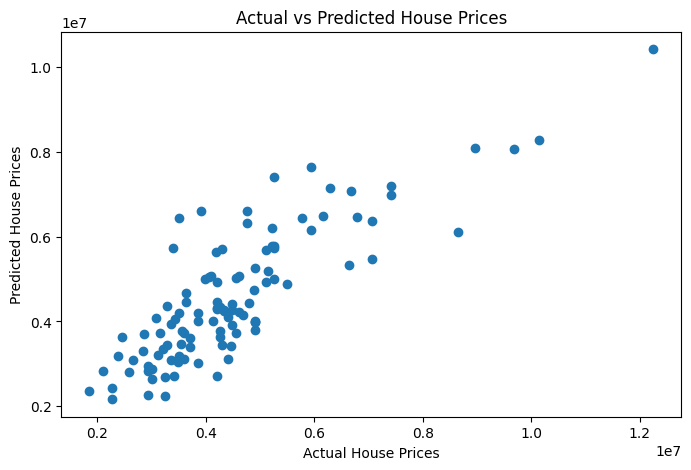

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()